# App-market analysis: Google Play Store
About 10,000 apps: data cleaning (sizes, installs, prices stored as text), then market structure. Which categories are crowded, where users are, how pricing relates to ratings and installs, and where the opportunities are.

In [1]:
import warnings, pathlib
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = pathlib.Path("images"); IMG.mkdir(exist_ok=True)
g = pd.read_csv("data/google_play_apps.csv")
g = g[g.Category.str.match(r"^[A-Z_]+$", na=False)]                     # drop one corrupted, column-shifted row
g = g.drop_duplicates("App")
g["Installs_n"] = g.Installs.str.replace(r"[+,]", "", regex=True).astype(float)
g["Price_usd"] = g.Price.str.replace("$", "", regex=False).astype(float)
g["Reviews"] = pd.to_numeric(g.Reviews)
g["Size_mb"] = g.Size.str.extract(r"([\d.]+)M", expand=False).astype(float).fillna(g.Size.str.extract(r"([\d.]+)k", expand=False).astype(float) / 1024)
g["Category"] = g.Category.str.replace("_", " ").str.title()
print(f"{len(g):,} unique apps, {g.Category.nunique()} categories, {(g.Type == 'Paid').mean():.1%} paid")

9,659 unique apps, 33 categories, 7.8% paid


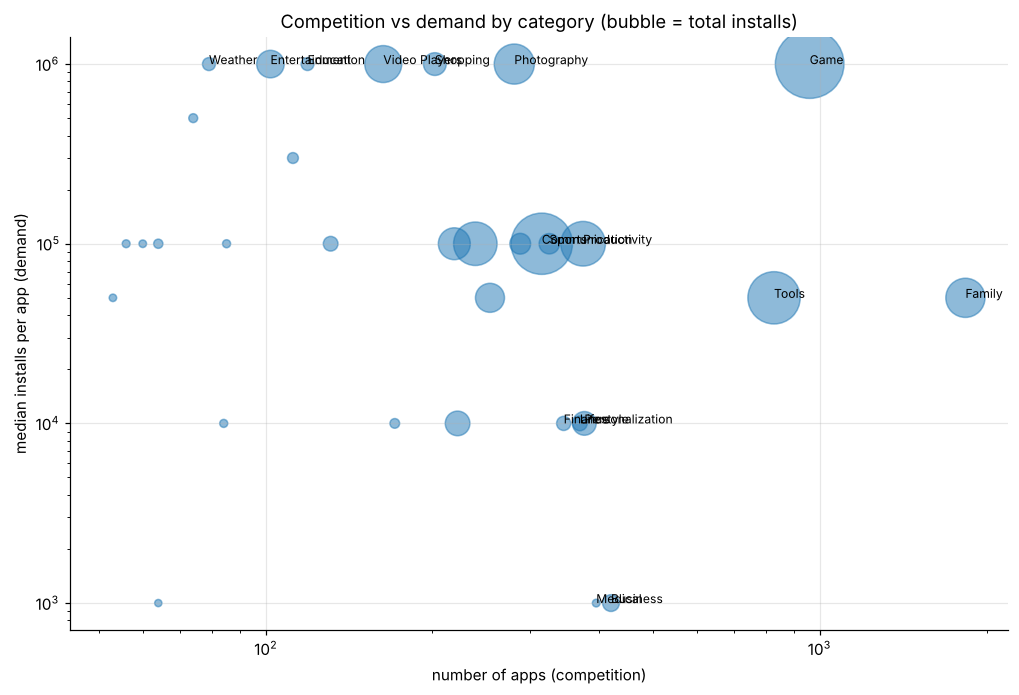

,apps,median_installs,avg_rating
Category,,,
Education,119,1000000.0,4.36
Shopping,202,1000000.0,4.23
Entertainment,102,1000000.0,4.14
Game,959,1000000.0,4.25
Photography,281,1000000.0,4.16
Video Players,163,1000000.0,4.04
Weather,79,1000000.0,4.24
House And Home,74,500000.0,4.15


In [2]:
cat = g.groupby("Category").agg(apps=("App", "size"), median_installs=("Installs_n", "median"), total_installs=("Installs_n", "sum"), avg_rating=("Rating", "mean"))
cat["installs per app (median)"] = cat.median_installs
fig, ax = plt.subplots(figsize=(11, 7))
ax.scatter(cat.apps, cat.median_installs, s=cat.total_installs / cat.total_installs.max() * 2000 + 20, alpha=0.5)
for n, r_ in cat.iterrows():
    if r_.apps > 300 or r_.median_installs >= 1e6: ax.annotate(n, (r_.apps, r_.median_installs), fontsize=8)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("number of apps (competition)"); ax.set_ylabel("median installs per app (demand)")
ax.set_title("Competition vs demand by category (bubble = total installs)"); plt.savefig(IMG / "market_map.png", bbox_inches="tight"); plt.show()
cat.sort_values("median_installs", ascending=False).head(8)[["apps", "median_installs", "avg_rating"]].round(2)

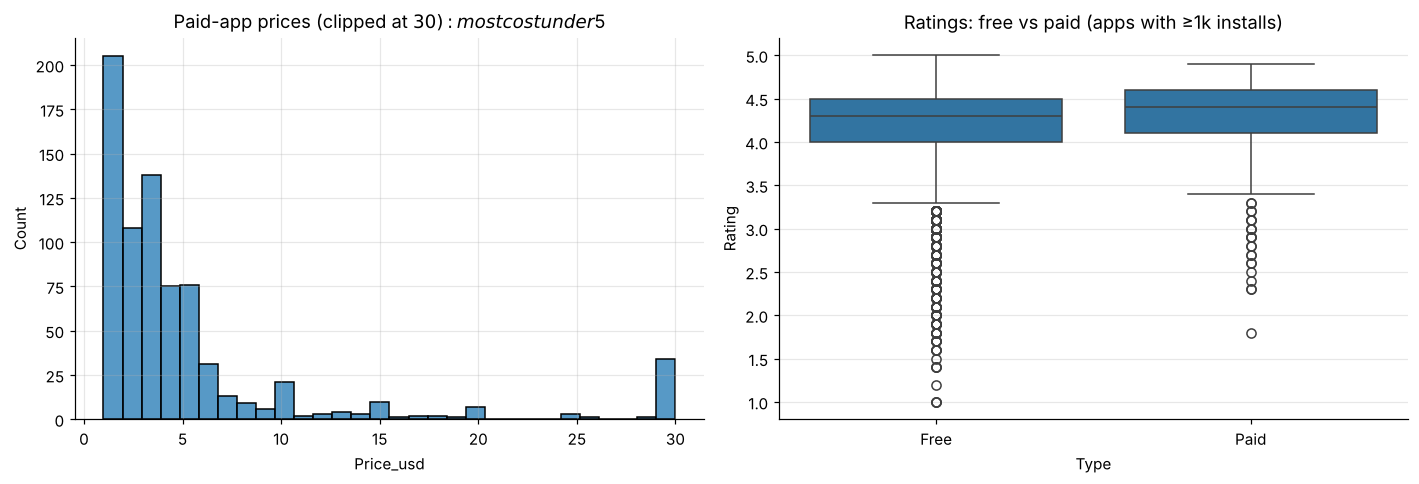

17 apps priced above $200, mostly 'I am rich' novelty apps:


,App,Category,Price_usd,Installs
4197,most expensive app (H),Family,399.99,100+
4362,💎 I'm rich,Lifestyle,399.99,"10,000+"
4367,I'm Rich - Trump Edition,Lifestyle,400.00,"10,000+"
5351,I am rich,Lifestyle,399.99,"100,000+"
5354,I am Rich Plus,Family,399.99,"10,000+"
5355,I am rich VIP,Lifestyle,299.99,"10,000+"


In [3]:
paid = g[g.Type == "Paid"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(paid.Price_usd.clip(upper=30), bins=30, ax=ax[0]); ax[0].set_title("Paid-app prices (clipped at $30): most cost under $5")
sns.boxplot(data=g[g.Installs_n >= 1000], x="Type", y="Rating", ax=ax[1]); ax[1].set_title("Ratings: free vs paid (apps with ≥1k installs)")
fig.tight_layout(); plt.show()
outliers = paid[paid.Price_usd > 200][["App", "Category", "Price_usd", "Installs"]]
print(f"{len(outliers)} apps priced above $200, mostly 'I am rich' novelty apps:"); outliers.head(6)

**Takeaways:** the categories where a typical app reaches about **1 million installs** include games and photography, which are crowded (hundreds of apps), as well as **education, entertainment and weather**, which have far fewer competitors. Those are the clearest niches, with real demand and less competition. Paid apps rate slightly higher (4.27 vs 4.15 on average) but have a **median of only 1,000 installs vs 100,000 for free apps**. For most products, freemium or subscription monetisation beats an upfront price. The $400 "I am rich" apps are a reminder to inspect outliers before averaging prices.